# Lightweight spatiotemporal feature combinations — XGBoost

**Run this only to screen combinations before any additional full-history model fits.**

Each configuration uses the same 10,000 historical training rows, up to 1,000 August 2025 held-out homes, and 220 tuned XGBoost trees. We keep the existing 47-word binary BoW baseline unchanged.

- **Feature combinations:** spline + geo context, spline + property-type quota, spline + market, spline + both geo context and type quota.
- **Residual combinations:** spline + tensor GAM and spline+geo + tensor GAM. Crucially, each GAM is fitted on *genuinely out-of-time residuals from that exact feature model* in earlier months (not the ordinary XGBoost residuals).

These numbers are a **development screen**, not comparable in absolute magnitude to the full 700-tree baseline. Run all cells, inspect the summary and failure diagnostics, and promote promising variants for subsequent three-month confirmation before full-data evaluation. No original notebooks or saved models are modified by the combination run.


In [1]:
# Locate the checkout from Jupyter/VS Code, including nested notebook folders.
from pathlib import Path
import os
import sys
_start = Path(os.environ.get("DATA_DASH_ROOT", Path.cwd())).expanduser().resolve()
ROOT = next((p for p in (_start, *_start.parents)
             if (p / "data.py").is_file() and (p / "models").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DATA_DASH_ROOT to your Data Dash checkout before running this notebook.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import display
from comparisons.spacetime_combination_screen import run_combination_screen, COMBINATIONS, CORRECTIONS

MONTH = "2025-08"
TRAIN_START = "2022-01-01"
TRAIN_CAP = 10000
VALIDATION_CAP = 1000
TREES = 220
CALIBRATION_FOLDS = 2
CALIBRATION_CAP = 300
RESIDUAL_STRENGTH = 0.5
SEED = 42
OUTPUT_DIR = "outputs/spacetime_combination_screen"
COMPARISON_VARIANTS = (
    "baseline",
    "splines",
    "geo_context",
    "splines_geo",
    "splines_market",
    "splines_tensor_gam",
    "splines_geo_tensor_gam",
)
print("Comparisons:", COMPARISON_VARIANTS)


Comparisons: ('baseline', 'splines', 'geo_context', 'splines_geo', 'splines_market', 'splines_tensor_gam', 'splines_geo_tensor_gam')


In [2]:
combo_scores, combo_predictions, combo_failures = run_combination_screen(
    validation_month=MONTH, train_start=TRAIN_START,
    train_cap=TRAIN_CAP, validation_cap=VALIDATION_CAP,
    trees=TREES, seed=SEED,
    calibration_folds=CALIBRATION_FOLDS,
    calibration_cap=CALIBRATION_CAP,
    residual_strength=RESIDUAL_STRENGTH,
    combinations=COMPARISON_VARIANTS,
    output_dir=OUTPUT_DIR,
)
display(combo_scores)
if combo_failures:
    display(combo_failures)


2025-08: baseline on 10,000 training homes
2025-08: splines on 10,000 training homes
2025-08: geo_context on 10,000 training homes
2025-08: splines_geo on 10,000 training homes
2025-08: splines_market on 10,000 training homes
2025-08: splines_tensor_gam on 10,000 training homes
2025-08: splines_geo_tensor_gam on 10,000 training homes
               variant     mdape      mape  delta_mdape_pp  delta_mape_pp
    splines_tensor_gam  9.971493 12.850781       -0.797118      -1.098251
               splines 10.162843 13.453334       -0.605768      -0.495698
splines_geo_tensor_gam 10.272272 13.005699       -0.496339      -0.943332
           splines_geo 10.637603 13.681077       -0.131008      -0.267954
        splines_market 10.687095 13.571948       -0.081517      -0.377083
              baseline 10.768611 13.949031        0.000000       0.000000
           geo_context 10.850362 13.906599        0.081751      -0.042432


,homes,mape,mdape,median_signed,variant,runtime_seconds,n_features,delta_mdape_pp,delta_mape_pp
0,1000,12.850781,9.971493,0.802957,splines_tensor_gam,17.079268,NaN,-0.797118,-1.098251
1,1000,13.453334,10.162843,3.204010,splines,9.556052,205.0,-0.605768,-0.495698
2,1000,13.005699,10.272272,1.453176,splines_geo_tensor_gam,17.543073,NaN,-0.496339,-0.943332
3,1000,13.681077,10.637603,4.123305,splines_geo,9.511666,210.0,-0.131008,-0.267954
4,1000,13.571948,10.687095,3.140204,splines_market,9.444894,221.0,-0.081517,-0.377083
5,1000,13.949031,10.768611,4.176564,baseline,7.277370,79.0,0.000000,0.000000
6,1000,13.906599,10.850362,3.940973,geo_context,7.610905,84.0,0.081751,-0.042432


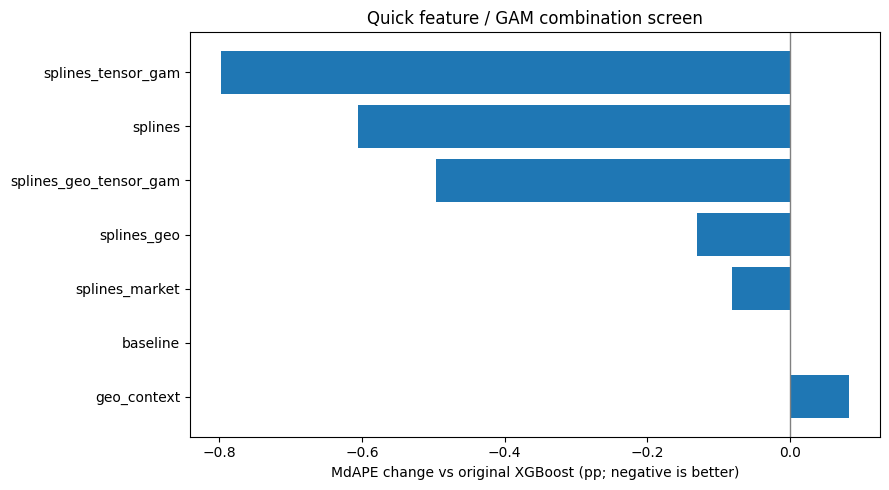

Saved summary, predictions, failures and settings in outputs/spacetime_combination_screen


In [3]:
import matplotlib.pyplot as plt
ranking = combo_scores.sort_values("delta_mdape_pp")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ranking.variant, ranking.delta_mdape_pp)
ax.axvline(0, color="gray", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("MdAPE change vs original XGBoost (pp; negative is better)")
ax.set_title("Quick feature / GAM combination screen")
fig.tight_layout()
plt.show()
print(f"Saved summary, predictions, failures and settings in {OUTPUT_DIR}")


### Interpreting the results

A combination must beat **spline-only**, not just the original baseline, to justify additional computational cost. Prefer gains in both MAPE and MdAPE across more than one development month, and avoid promoting variants based on tiny improvements from this single holdout.

We should run a larger three-month follow-up for any promising **pure feature** combination, then only run it with all historical sales and the 700-tree XGBoost configuration. For GAM combinations, full-strength calibration must also be recomputed for the combined model's own out-of-time residuals; **do not reuse the tensor-GAM calibration from original XGBoost**.
